# UTS GSD SEMESTER GANJIL 2026
Salma Latifa Kamil
NIM: 24031554089
Kelas: 2024A

In [ ]:
import pandas as pd
import os
from tqdm import tqdm
from collections import Counter
import numpy as np
from scipy.sparse import coo_matrix
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import coo_matrix
import time

In [1]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "helloHello")

# 1. Pendahuluan

## 1.2

In [34]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name
        )

In [35]:
def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) "
            "WHERE a.name = $name "
            "RETURN friend.name AS friend_name "
            "ORDER BY friend.name",
            name=name
        )

        for record in result:
            print(record["friend_name"])

In [36]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**1. Apa nama database yang digunakan pada tutorial ini?**
= Nama database yang digunakan "neo4j" (terlihat pada parameter database=neo4j)

**2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**
= Terdapat beberapa sintaks cypher seperti:
- DDL: CREATE DATABASE, CREATE CONSTRAINT, dan CREATE INDEX.
- DML: CREATE, MATCH, MERGE, SET, dan DELETE.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**
= Graf yang dibuat adalah directed graph dengan node 'Person' dan relationship 'KNOWS'. Arthur menjadi sumber relasi ke Guinevere, Lancelot, dan Merlin. Sehingga relationship berjalan dari Arthur menuju tiap 'friend name', tetapi bukan otomatis berbalik dari teman ke arthur juga.

## 1.3

In [ ]:
csv_file_path = os.path.join("retailrocket", "events.csv")

data_waktu = pd.read_csv(csv_file_path, usecols=["timestamp"])
data_waktu["tanggal"] = pd.to_datetime(data_waktu["timestamp"], unit="ms")

print("Tanggal paling awal:", data_waktu["tanggal"].min())
print("Tanggal paling akhir:", data_waktu["tanggal"].max())

Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000


In [ ]:
csv_file_path = "retailrocket/events.csv"
output_folder = "retailrocket/filtered"

os.makedirs(output_folder, exist_ok=True)

p1_file = os.path.join(output_folder, "events_p1.csv")
p2_file = os.path.join(output_folder, "events_p2.csv")

for file_path in [p1_file, p2_file]:
    if os.path.exists(file_path):
        os.remove(file_path)

p1_start = pd.Timestamp("2015-05-05")
p1_end = pd.Timestamp("2015-05-16")

p2_start = pd.Timestamp("2015-05-16")
p2_end = pd.Timestamp("2015-05-27")

jumlah_p1 = 0
jumlah_p2 = 0

for chunk in pd.read_csv(csv_file_path, chunksize=200_000):
    chunk["tanggal"] = pd.to_datetime(
        chunk["timestamp"], unit="ms"
    )

    data_p1 = chunk[
        (chunk["tanggal"] >= p1_start) &
        (chunk["tanggal"] < p1_end)
    ].drop(columns="tanggal")

    data_p2 = chunk[
        (chunk["tanggal"] >= p2_start) &
        (chunk["tanggal"] < p2_end)
    ].drop(columns="tanggal")

    if not data_p1.empty:
        data_p1.to_csv(
            p1_file,
            mode="a",
            header=(jumlah_p1 == 0),
            index=False
        )
        jumlah_p1 += len(data_p1)

    if not data_p2.empty:
        data_p2.to_csv(
            p2_file,
            mode="a",
            header=(jumlah_p2 == 0),
            index=False
        )
        jumlah_p2 += len(data_p2)

print("Jumlah interaksi P1:", jumlah_p1)
print("Jumlah interaksi P2:", jumlah_p2)
print("File P1:", p1_file)
print("File P2:", p2_file)

Jumlah interaksi P1: 223030
Jumlah interaksi P2: 238566
File P1: retailrocket/filtered\events_p1.csv
File P2: retailrocket/filtered\events_p2.csv


In [5]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "helloHello")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()

    with driver.session(database=DATABASE) as session:
        print("Jumlah node berdasarkan label:")

        result = session.run("""
            MATCH (n)
            RETURN labels(n) AS labels, count(*) AS jumlah
            ORDER BY labels
        """)

        records = list(result)

        if records:
            for record in records:
                print(record["labels"], record["jumlah"])
        else:
            print("Database belum memiliki node.")

        print("\nJumlah relasi berdasarkan tipe:")

        result = session.run("""
            MATCH ()-[r]->()
            RETURN type(r) AS tipe, count(*) AS jumlah
            ORDER BY tipe
        """)

        records = list(result)

        if records:
            for record in records:
                print(record["tipe"], record["jumlah"])
        else:
            print("Belum ada relasi.")

finally:
    driver.close()

C:\Users\Latifa\AppData\Local\Temp\ipykernel_8252\535110359.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Jumlah node berdasarkan label:
['Item'] 101090
['Person'] 4
['Visitor'] 241244

Jumlah relasi berdasarkan tipe:
ADDED_TO_CART 11134
BOUGHT 3600
KNOWS 3
SIMILAR_TO 5
VIEWED 446862


In [6]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
    """)
    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemId IS UNIQUE
    """)

In [7]:
def import_batch(tx, batch, period):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp,
            period: $period
        }]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp,
            period: $period
        }]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid,
            period: $period
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch, period=period)

In [8]:
def import_csv(driver, csv_path, period, batch_size=10000):
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"File tidak ditemukan: {csv_path}")

    total_rows = sum(1 for _ in open(csv_path, encoding="utf-8")) - 1
    total_chunks = (total_rows + batch_size - 1) // batch_size

    row_offset = 0

    with driver.session(database=DATABASE) as session:
        chunks = pd.read_csv(csv_path, chunksize=batch_size)

        for chunk in tqdm(chunks, total=total_chunks, desc=f"Import {period}"):
            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            chunk["eventId"] = [
                f"{period}_{i}"
                for i in range(row_offset, row_offset + len(chunk))
            ]
            row_offset += len(chunk)

            records = chunk.to_dict(orient="records")

            session.write_transaction(
                import_batch, records, period
            )

    print(f"{period} selesai: {total_rows} baris")

In [ ]:
try:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        create_constraints(session)

    import_csv(driver, p1_file, "P1")
    import_csv(driver, p2_file, "P2")
    print("Import P1 dan P2 selesai.")

finally:
    driver.close()

C:\Users\Latifa\AppData\Local\Temp\ipykernel_10472\672035969.py:4: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()
Exception ignored in: <function tqdm.__del__ at 0x00000275F3193A60>
Traceback (most recent call last):
  File "c:\Users\Latifa\SEMESTER_5\GSD\UTS\myvenv\Lib\site-packages\tqdm\std.py", line 1154, in __del__
    self.close()
  File "c:\Users\Latifa\SEMESTER_5\GSD\UTS\myvenv\Lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'
Import P1: 100%|██████████| 23/23 [00:51<00:00,  2.22s/it]


P1 selesai: 223030 baris


Import P2: 100%|██████████| 24/24 [00:42<00:00,  1.78s/it]

P2 selesai: 238566 baris
Import P1 dan P2 selesai.


In [ ]:
try:
    with driver.session(database=DATABASE) as session:
        result = session.run("""
            MATCH (n)
            WHERE n:Visitor OR n:Item
            WITH labels(n) AS label, count(*) AS jumlah
            RETURN label, jumlah
            ORDER BY label
        """)

        print("Jumlah node:")
        for record in result:
            print(record["label"], record["jumlah"])

        result = session.run("""
            MATCH ()-[r]->()
            WHERE r.period IN ['P1', 'P2']
            RETURN r.period AS periode,
                   type(r) AS tipe,
                   count(*) AS jumlah
            ORDER BY periode, tipe
        """)

        print("\nJumlah relasi:")
        for record in result:
            print(record["periode"], record["tipe"], record["jumlah"])

finally:
    driver.close()

Jumlah node:
['Item'] 101090
['Visitor'] 241244

Jumlah relasi:
P1 ADDED_TO_CART 5644
P1 BOUGHT 1868
P1 VIEWED 215518
P2 ADDED_TO_CART 5490
P2 BOUGHT 1732
P2 VIEWED 231344


# 2. Soal UTS

## 2.1 EDA

### 2.1.1

Periode yang ditentukan adalah:
- P1 (training): 05 Mei 2015 - 15 Mei 2015
- P2 (testing) : 16 Mei 2015 - 26 Mei 2015

Berikut potongan code dari cell ke-2 pada bagian 1.3 yang digunakan untuk menentukan rentang waktu masing-masing periode.
``` 
p1_start = pd.Timestamp("2015-05-05")
p1_end = pd.Timestamp("2015-05-16")

p2_start = pd.Timestamp("2015-05-16")
p2_end = pd.Timestamp("2015-05-27")
```

### 2.1.2

Proses filtering dilakukan dengan mengubah kolom timestamp dalam milidetik menjadi format datetime menggunakan `pd.to_datetime()`. Lalu data dipisahkan berdasarkan rentang waktu P1 dan P2 yang telah ditentukan sebelumnya. Hasil filtering disimpan ke file CSV yaitu `events_p1.csv` untuk data training dan `events_p2.csv` untuk data testing. Berikut potongan code
```
for chunk in pd.read_csv(csv_file_path, chunksize=200_000):
    chunk["tanggal"] = pd.to_datetime(
        chunk["timestamp"], unit="ms"
    )

    data_p1 = chunk[
        (chunk["tanggal"] >= p1_start) &
        (chunk["tanggal"] < p1_end)
    ].drop(columns="tanggal")

    data_p2 = chunk[
        (chunk["tanggal"] >= p2_start) &
        (chunk["tanggal"] < p2_end)
    ].drop(columns="tanggal")

    if not data_p1.empty:
        data_p1.to_csv(
            p1_file,
            mode="a",
            header=(jumlah_p1 == 0),
            index=False
        )
        jumlah_p1 += len(data_p1)

    if not data_p2.empty:
        data_p2.to_csv(
            p2_file,
            mode="a",
            header=(jumlah_p2 == 0),
            index=False
        )
        jumlah_p2 += len(data_p2)
```

### 2.1.3

In [50]:
try:
    with driver.session(database=DATABASE) as session:
        result = session.run("""
            MATCH (n)
            WHERE n:Visitor OR n:Item
            RETURN labels(n) AS label, count(*) AS jumlah
            ORDER BY label
        """)

        df_node = pd.DataFrame(
            [record.data() for record in result]
        )

    display(df_node)

finally:
    driver.close()

,label,jumlah
0,[Item],101090
1,[Visitor],241244


`MATCH (n)` mengambil node dalam graph, `WHERE n:Visitor OR n:Item` membatasi hasil pada node visitor dan item. `labels(n)` mengambil label node dan `count(*)` menghitung jumlah node tiap label. Query menghasilkan visitor sebanyak 241.244 node dan item sebanyak 101.090 node

In [51]:
try:
    with driver.session(database=DATABASE) as session:
        result = session.run("""
            MATCH ()-[r]->()
            WHERE r.period IN ['P1', 'P2']
            RETURN r.period AS periode,
                   type(r) AS tipe_relasi,
                   count(*) AS jumlah
            ORDER BY periode, tipe_relasi
        """)

        df_relasi = pd.DataFrame(
            [record.data() for record in result]
        )

    display(df_relasi)

finally:
    driver.close()

,periode,tipe_relasi,jumlah
0,P1,ADDED_TO_CART,5644
1,P1,BOUGHT,1868
2,P1,VIEWED,215518
3,P2,ADDED_TO_CART,5490
4,P2,BOUGHT,1732
5,P2,VIEWED,231344


`MATCH ()-[r]->()` mengambil relationship dalam graph, `WHERE r.period IN ['P1', 'P2']` membatasi hasil pada periode training dan testing, `type(r)` mengambil jenis relationship, dan `count(*)` menghitung jumlahnya untuk setiap kombinasi periode dan jenis aktivitas. Query menunjukkan bahwa graph terdiri dari tiga jenis relationship, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT, pada masing-masing periode.

### 2.1.4

In [52]:
try:
    with driver.session(database=DATABASE) as session:
        result = session.run("""
            MATCH (v:Visitor)-[r]->(i:Item)
            WHERE r.period = 'P1'
            RETURN v.visitorId AS visitorId,
                   i.itemId AS itemId,
                   type(r) AS eventType
        """)

        data = [record.data() for record in result]

finally:
    driver.close()

df_interaksi = pd.DataFrame(data)

print("Jumlah baris interaksi:", len(df_interaksi))
print(df_interaksi.head())

Jumlah baris interaksi: 223030
   visitorId  itemId eventType
0    1402032  155412    VIEWED
1     626394  376341    VIEWED
2     482297  388514    VIEWED
3      99319  464812    VIEWED
4     102363  464812    VIEWED


In [ ]:
bobot_event = {
    "VIEWED": 1,
    "ADDED_TO_CART": 2,
    "BOUGHT": 3
}

df_interaksi["bobot"] = df_interaksi["eventType"].map(bobot_event)

# Ubah visitorid dan item menjadi indeks matriks
visitor_index, daftar_visitor = pd.factorize(
    df_interaksi["visitorId"], sort=True
)

item_index, daftar_item = pd.factorize(
    df_interaksi["itemId"], sort=True
)

# Matrix
VSM_visitor = coo_matrix(
    (
        df_interaksi["bobot"].to_numpy(),
        (visitor_index, item_index)
    ),
    shape=(len(daftar_visitor), len(daftar_item))
).tocsr()

print("Jumlah visitor:", len(daftar_visitor))
print("Jumlah item:", len(daftar_item))
print("Shape VSM:", VSM_visitor.shape)
print("Jumlah nilai bukan nol:", VSM_visitor.nnz)
print("Ukuran matriks:", VSM_visitor.shape[0], "x", VSM_visitor.shape[1])

Jumlah visitor: 118134
Jumlah item: 66326
Shape VSM: (118134, 66326)
Jumlah nilai bukan nol: 174647
Ukuran matriks: 118134 x 66326


Matriks VSM yang dihasilkan memiliki shape (118134, 66326), yang berarti terdapat 118.134 visitor unik dan 66.326 item unik pada periode P1. Matriks memiliki 174.647 nilai bukan nol yang lebih kecil daripada jumlah baris interaksi awal karena interaksi berulang antara visitor dan item yang sama dijumlahkan ketika matriks diubah ke format CSR.

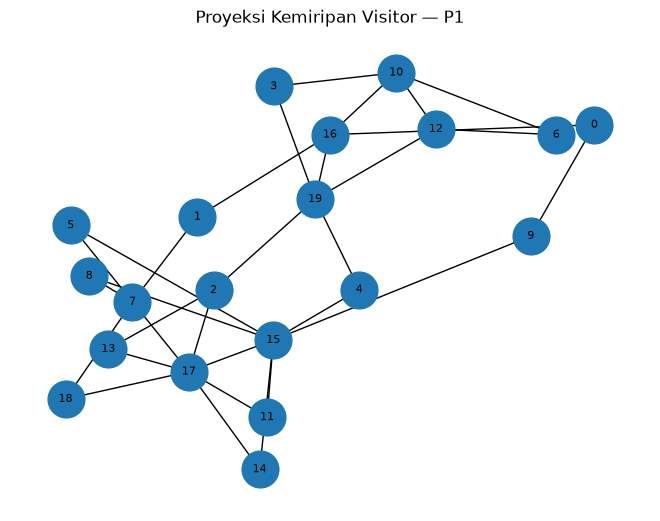

Jumlah node pada graf sampel: 20
Jumlah edge pada graf sampel: 30


In [66]:
# Pilih 20 visitor dengan total bobot interaksi tertinggi
total_bobot = np.asarray(VSM_visitor.sum(axis=1)).ravel()
visitor_terpilih = np.argsort(total_bobot)[-20:]

VSM_sampel = VSM_visitor[visitor_terpilih]

# Hitung kemiripan antar-visitor yang terpilih
similarity = cosine_similarity(VSM_sampel)

# Bentuk graf visitor
G_visitor = nx.Graph()

for i, idx in enumerate(visitor_terpilih):
    G_visitor.add_node(i, visitorId=int(daftar_visitor[idx]))

# Hubungkan setiap visitor dengan dua tetangga paling mirip
for i in range(len(visitor_terpilih)):
    tetangga = np.argsort(similarity[i])[-3:-1]

    for j in tetangga:
        nilai = similarity[i, j]

        if nilai > 0:
            G_visitor.add_edge(i, j, weight=float(nilai))

# Visualisasi
pos = nx.spring_layout(G_visitor, seed=42)

nx.draw(
    G_visitor,
    pos,
    with_labels=True,
    node_size=700,
    font_size=8
)

plt.title("Proyeksi Kemiripan Visitor — P1")
plt.show()

print("Jumlah node pada graf sampel:", G_visitor.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_visitor.number_of_edges())

### 2.1.5

In [68]:
# Ubah ID item dan visitor menjadi indeks matriks
item_index, daftar_item = pd.factorize(
    df_interaksi["itemId"], sort=True
)

visitor_index, daftar_visitor_item = pd.factorize(
    df_interaksi["visitorId"], sort=True
)

# Bentuk matriks Item x Visitor
VSM_item = coo_matrix(
    (
        df_interaksi["bobot"].to_numpy(),
        (item_index, visitor_index)
    ),
    shape=(len(daftar_item), len(daftar_visitor_item))
).tocsr()

print("Jumlah item:", len(daftar_item))
print("Jumlah visitor:", len(daftar_visitor_item))
print("Shape VSM item:", VSM_item.shape)
print("Jumlah nilai bukan nol:", VSM_item.nnz)

Jumlah item: 66326
Jumlah visitor: 118134
Shape VSM item: (66326, 118134)
Jumlah nilai bukan nol: 174647


Kebalikan dari karakteristik Visitor, Matriks VSM item memiliki shape (66326, 118134). Jumlah nilai bukan nol sama, yaitu 174647

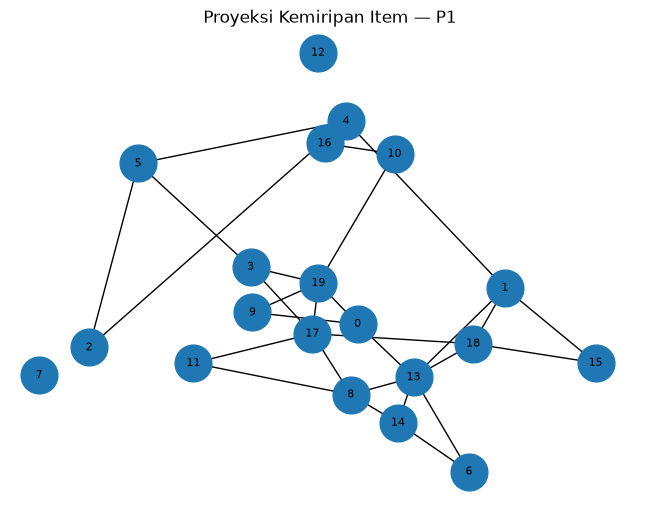

Jumlah node graf item: 20
Jumlah edge graf item: 28


In [ ]:
# 20 item dengan total bobot interaksi tertinggi
total_bobot_item = np.asarray(VSM_item.sum(axis=1)).ravel()
item_terpilih = np.argsort(total_bobot_item)[-20:]

VSM_sampel_item = VSM_item[item_terpilih]

similarity_item = cosine_similarity(VSM_sampel_item)

G_item = nx.Graph()
for i, idx in enumerate(item_terpilih):
    G_item.add_node(i, itemId=int(daftar_item[idx]))

for i in range(len(item_terpilih)):
    tetangga = np.argsort(similarity_item[i])[-3:-1]

    for j in tetangga:
        nilai = similarity_item[i, j]

        if nilai > 0:
            G_item.add_edge(i, j, weight=float(nilai))

pos = nx.spring_layout(G_item, seed=42)

nx.draw(
    G_item,
    pos,
    with_labels=True,
    node_size=700,
    font_size=8
)

plt.title("Proyeksi Kemiripan Item — P1")
plt.show()

print("Jumlah node graf item:", G_item.number_of_nodes())
print("Jumlah edge graf item:", G_item.number_of_edges())

### 2.1.6

In [ ]:
memori_visitor = (
    VSM_visitor.data.nbytes
    + VSM_visitor.indices.nbytes
    + VSM_visitor.indptr.nbytes
) / (1024 ** 2)

memori_item = (
    VSM_item.data.nbytes
    + VSM_item.indices.nbytes
    + VSM_item.indptr.nbytes
) / (1024 ** 2)

density_visitor = (
    VSM_visitor.nnz
    / (VSM_visitor.shape[0] * VSM_visitor.shape[1])
) * 100

density_item = (
    VSM_item.nnz
    / (VSM_item.shape[0] * VSM_item.shape[1])
) * 100

df_perbandingan = pd.DataFrame({
    "Aspek": [
        "Jumlah baris",
        "Jumlah kolom",
        "Nilai bukan nol",
        "Kepadatan (%)",
        "Memori sparse (MB)"
    ],
    "VSM Visitor": [
        VSM_visitor.shape[0],
        VSM_visitor.shape[1],
        VSM_visitor.nnz,
        round(density_visitor, 6),
        round(memori_visitor, 2)
    ],
    "VSM Item": [
        VSM_item.shape[0],
        VSM_item.shape[1],
        VSM_item.nnz,
        round(density_item, 6),
        round(memori_item, 2)
    ]
})

display(df_perbandingan)

,Aspek,VSM Visitor,VSM Item
0,Jumlah baris,118134.000000,66326.000000
1,Jumlah kolom,66326.000000,118134.000000
2,Nilai bukan nol,174647.000000,174647.000000
3,Kepadatan (%),0.002229,0.002229
4,Memori sparse (MB),2.450000,2.250000


In [ ]:
# Sampel 20 visitor dan 20 item
VSM_sampel_visitor = VSM_visitor[visitor_terpilih]
VSM_sampel_item = VSM_item[item_terpilih]

# Waktu cosine similarity visitor
start = time.perf_counter()
sim_visitor = cosine_similarity(VSM_sampel_visitor)
waktu_visitor = time.perf_counter() - start

# Waktu cosine similarity item
start = time.perf_counter()
sim_item = cosine_similarity(VSM_sampel_item)
waktu_item = time.perf_counter() - start

print(f"Waktu similarity Visitor: {waktu_visitor:.6f} detik")
print(f"Waktu similarity Item: {waktu_item:.6f} detik")

Waktu similarity Visitor: 0.007877 detik
Waktu similarity Item: 0.006015 detik


VSM Visitor memiliki 118.134 baris dan 66.326 kolom, sedangkan VSM Item memiliki 66.326 baris dan 118.134 kolom. Keduanya memiliki 174.647 nilai bukan nol dan kepadatan matriks sebesar 0,002229%, sehingga tingkat sparsity keduanya sama. Dari sisi efisiensi memori, VSM Item menggunakan memori sparse sebesar 2,25 MB, yang lebih kecil dari VSM Visitor (2,45 MB). Waktu perhitungan similarity pada sampel yang diuji juga lebih singkat untuk VSM Item, yaitu 0,006015 detik dibandingkan VSM Visitor sebesar 0,007877 detik. 

Jadi, VSM Item sedikit lebih efisien dalam penggunaan memori dan waktu perhitungan similarity. Tetapi bukan berarti selalu lebih baik, karena waktu pengukuran bergantung pada sampel dan kondisi eksekusi. Dalam Pemilihan proyeksi seharusnya tetap bergantung pada tujuan analisis dimana VSM Visitor lebih sesuai untuk melihat kemiripan antar-pengunjung dan VSM Item lebih sesuai untuk melihat kemiripan antar-produk.

### 2.1.7

#### 2.1.7.a

In [77]:
pasangan_item = []

for i in range(len(item_terpilih)):
    for j in range(i + 1, len(item_terpilih)):
        nilai_similarity = float(similarity_item[i, j])

        if nilai_similarity > 0:
            pasangan_item.append({
                "itemId1": int(daftar_item[item_terpilih[i]]),
                "itemId2": int(daftar_item[item_terpilih[j]]),
                "similarity": nilai_similarity
            })

df_similarity = pd.DataFrame(pasangan_item)

df_top5 = (
    df_similarity
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(df_top5)

,itemId1,itemId2,similarity
0,320130,7943,0.175749
1,320130,318333,0.166257
2,318333,7943,0.149429
3,315543,369447,0.142742
4,315543,318333,0.130447


#### 2.1.7.b

In [78]:
def simpan_similarity(tx, records):
    query = """
    UNWIND $records AS row
    MATCH (i1:Item {itemId: row.itemId1})
    MATCH (i2:Item {itemId: row.itemId2})
    MERGE (i1)-[r:SIMILAR_TO]->(i2)
    SET r.similarity = row.similarity,
        r.method = 'cosine',
        r.period = 'P1'
    RETURN count(r) AS jumlah
    """
    result = tx.run(query, records=records)
    return result.single()["jumlah"]


records = df_top5.to_dict(orient="records")

try:
    with driver.session(database=DATABASE) as session:
        jumlah = session.write_transaction(
            simpan_similarity, records
        )
        print("Relasi similarity diproses:", jumlah)

finally:
    driver.close()

Relasi similarity diproses: 5


### 2.1.8

In [ ]:
# ID dari 20 item sampel yang dipakai di 2.1.5–2.1.7
items_sampel = set(
    int(daftar_item[idx]) for idx in item_terpilih
)

interaksi_sampel = df_interaksi[
    df_interaksi["itemId"].isin(items_sampel)
].copy()

visitor_sampel = (
    interaksi_sampel["visitorId"]
    .value_counts()
    .head(10)
    .index
)

interaksi_sampel = interaksi_sampel[
    interaksi_sampel["visitorId"].isin(visitor_sampel)
]

print("Jumlah item sampel:", len(items_sampel))
print("Jumlah visitor sampel:", len(visitor_sampel))
print("Jumlah baris interaksi sampel:", len(interaksi_sampel))

Jumlah item sampel: 20
Jumlah visitor sampel: 10
Jumlah baris interaksi sampel: 209


In [ ]:
G_sebelum = nx.Graph()

for visitor in visitor_sampel:
    visitor = int(visitor)
    G_sebelum.add_node(
        ("Visitor", visitor),
        label=f"V{visitor}"
    )

for item in items_sampel:
    G_sebelum.add_node(
        ("Item", item),
        label=f"I{item}"
    )

for row in interaksi_sampel.itertuples(index=False):
    visitor = int(row.visitorId)
    item = int(row.itemId)

    G_sebelum.add_edge(
        ("Visitor", visitor),
        ("Item", item),
        tipe=row.eventType
    )

G_sesudah = G_sebelum.copy()
for row in df_top5.itertuples(index=False):
    item1 = int(row.itemId1)
    item2 = int(row.itemId2)

    if (
        ("Item", item1) in G_sesudah
        and ("Item", item2) in G_sesudah
    ):
        G_sesudah.add_edge(
            ("Item", item1),
            ("Item", item2),
            tipe="SIMILAR_TO",
            similarity=float(row.similarity)
        )

print("Sebelum:", G_sebelum.number_of_nodes(),
      "node,", G_sebelum.number_of_edges(), "edge")

print("Sesudah:", G_sesudah.number_of_nodes(),
      "node,", G_sesudah.number_of_edges(), "edge")

Sebelum: 30 node, 41 edge
Sesudah: 30 node, 46 edge


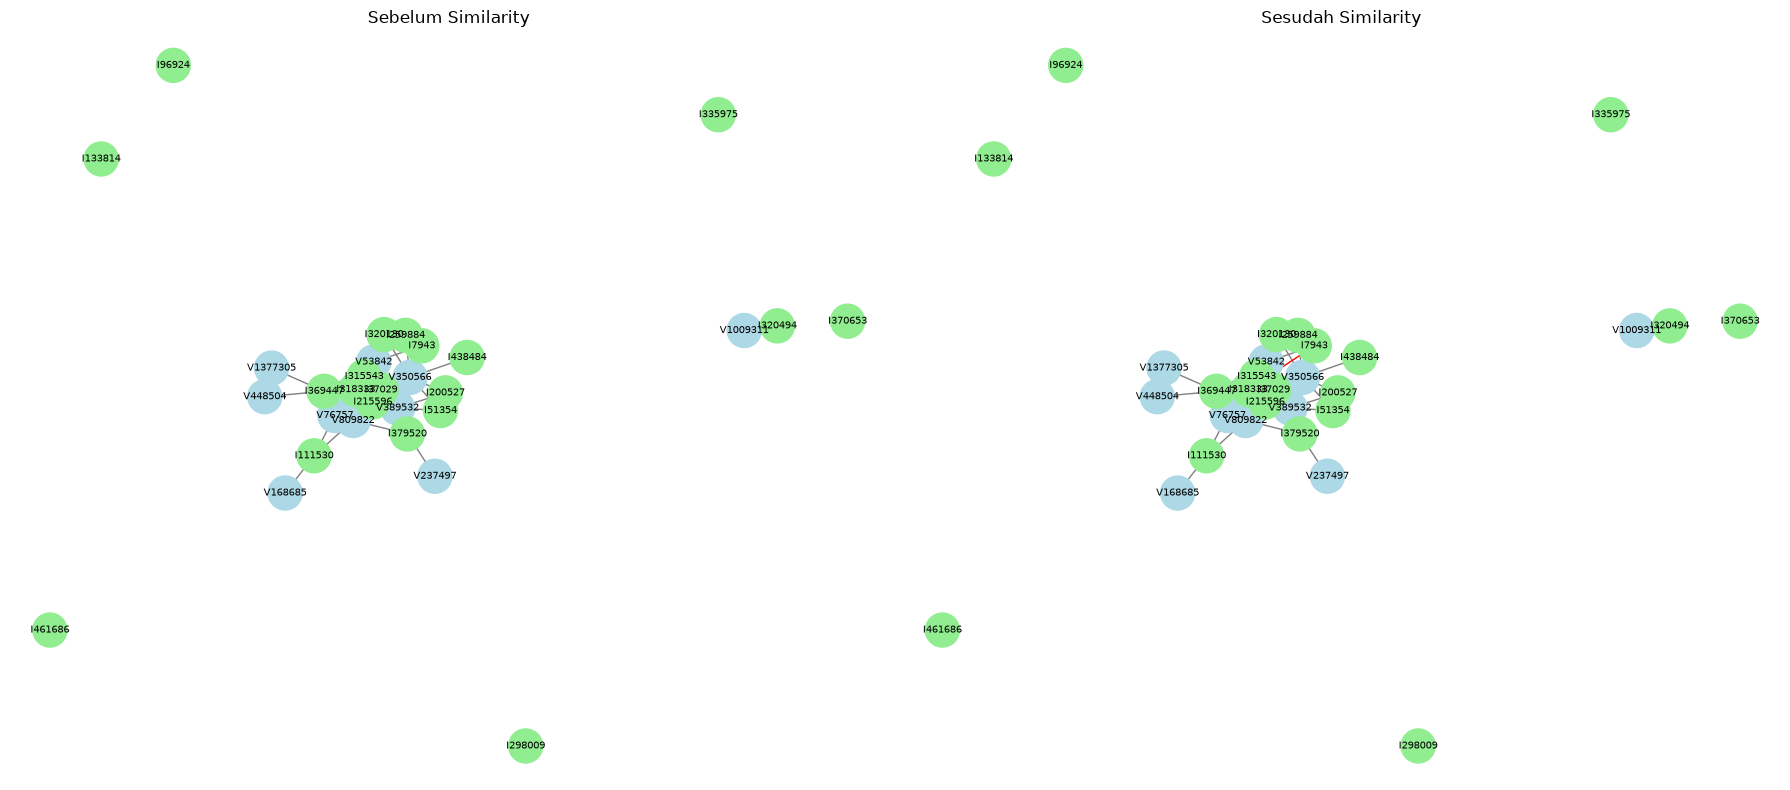

In [81]:
pos = nx.spring_layout(G_sebelum, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, G, judul in [
    (axes[0], G_sebelum, "Sebelum Similarity"),
    (axes[1], G_sesudah, "Sesudah Similarity")
]:
    warna_node = [
        "lightblue" if node[0] == "Visitor" else "lightgreen"
        for node in G.nodes()
    ]

    warna_edge = [
        "red" if data.get("tipe") == "SIMILAR_TO" else "gray"
        for _, _, data in G.edges(data=True)
    ]

    nx.draw(
        G,
        pos,
        ax=ax,
        labels=nx.get_node_attributes(G, "label"),
        node_color=warna_node,
        edge_color=warna_edge,
        node_size=600,
        font_size=7,
        with_labels=True
    )

    ax.set_title(judul)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.2 Analysis

### 2.2.1

#### 2.2.1.a

In [ ]:
selected_user = 99510
user_to_idx = {user: idx for idx, user in enumerate(user_ids)}
target_idx = user_to_idx[selected_user]

In [ ]:
try:
    with driver.session(database=DATABASE) as session:
        hasil_p1 = session.run("""
            MATCH (v:Visitor)-[r]->(i:Item)
            WHERE r.period = 'P1'
              AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
            RETURN v.visitorId AS visitor_id,
                   i.itemId AS item_id,
                   type(r) AS event_type
        """)

        interactions_p1 = pd.DataFrame(
            [record.data() for record in hasil_p1]
        )

        hasil_p2 = session.run("""
            MATCH (v:Visitor)-[r]->(:Item)
            WHERE r.period = 'P2'
              AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
            RETURN DISTINCT v.visitorId AS visitor_id
        """)

        users_p2 = {
            record["visitor_id"] for record in hasil_p2
        }
finally:
    driver.close()

print("Jumlah interaksi P1:", len(interactions_p1))
print("Jumlah user aktif di P2:", len(users_p2))
display(interactions_p1.head())

Jumlah interaksi P1: 223030
Jumlah user aktif di P2: 129109


,visitor_id,item_id,event_type
0,1402032,155412,VIEWED
1,626394,376341,VIEWED
2,482297,388514,VIEWED
3,99319,464812,VIEWED
4,102363,464812,VIEWED


In [ ]:
bobot_event = {
    "VIEWED": 1,
    "ADDED_TO_CART": 2,
    "BOUGHT": 3
}

interactions_p1["weight"] = (
    interactions_p1["event_type"].map(bobot_event)
)

train = (
    interactions_p1
    .groupby(["visitor_id", "item_id"], as_index=False)
    ["weight"]
    .sum()
)

user_ids = sorted(train["visitor_id"].unique())
item_ids = sorted(train["item_id"].unique())

user_to_idx = {
    user: idx for idx, user in enumerate(user_ids)
}

item_to_idx = {
    item: idx for idx, item in enumerate(item_ids)
}

rows = train["visitor_id"].map(user_to_idx).to_numpy()
cols = train["item_id"].map(item_to_idx).to_numpy()
values = train["weight"].to_numpy(dtype=float)

user_item_matrix = coo_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
).tocsr()

print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Ukuran matriks:", user_item_matrix.shape)

Jumlah user: 118134
Jumlah item: 66326
Ukuran matriks: (118134, 66326)


In [ ]:
jumlah_item_per_user = (
    train.groupby("visitor_id")["item_id"].nunique()
)

kandidat_idx = np.array([
    idx for idx, user in enumerate(user_ids)
    if user != selected_user
    and jumlah_item_per_user.loc[user] >= 2
])

similarity = cosine_similarity(
    user_item_matrix[target_idx],
    user_item_matrix[kandidat_idx]
).flatten()

urutan = np.argsort(similarity)[::-1]
urutan = urutan[similarity[urutan] > 0]

if len(urutan) < 5:
    raise ValueError(
        "Belum ditemukan 5 tetangga dengan similarity positif "
        "dan minimal 2 item unik."
    )

neighbor_indices = kandidat_idx[urutan[:5]]
neighbor_similarities = similarity[urutan[:5]]

neighbors_df = pd.DataFrame({
    "neighbor_id": [user_ids[idx] for idx in neighbor_indices],
    "jumlah_item": [
        jumlah_item_per_user.loc[user_ids[idx]]
        for idx in neighbor_indices
    ],
    "similarity": neighbor_similarities
})

display(neighbors_df)

,neighbor_id,jumlah_item,similarity
0,1178774,2,0.600481
1,280924,2,0.577350
2,133910,2,0.577350
3,482631,2,0.547723
4,1304960,21,0.481051


In [108]:
neighbor_matrix = user_item_matrix[neighbor_indices]

item_scores = np.asarray(
    neighbor_matrix.T @ neighbor_similarities
).ravel()

seen_items = set(
    train.loc[
        train["visitor_id"] == selected_user,
        "item_id"
    ]
)

recommendation_df = pd.DataFrame({
    "item_id": item_ids,
    "score": item_scores
})

recommendation_df = recommendation_df[
    (recommendation_df["score"] > 0)
    & (~recommendation_df["item_id"].isin(seen_items))
]

recommendation_df = (
    recommendation_df
    .sort_values(
        ["score", "item_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

top5_recommendations = recommendation_df.head(5).copy()

print("User target:", selected_user)
print("Jumlah rekomendasi:", len(top5_recommendations))
display(top5_recommendations)

User target: 99510
Jumlah rekomendasi: 5


,item_id,score
0,200425,1.148203
1,183235,0.962102
2,244252,0.962102
3,264233,0.962102
4,34125,0.481051


#### 2.2.1.b

In [ ]:
top3_recommendations = top5_recommendations.head(3).copy()

print("User target:", selected_user)
print("Tiga item rekomendasi:")
display(top3_recommendations)

User target: 99510
Tiga item rekomendasi:


,item_id,score
0,200425,1.148203
1,183235,0.962102
2,244252,0.962102


In [111]:
driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    with driver.session(database=DATABASE) as session:
        hasil = session.run("""
            MATCH (v:Visitor)-[r]->(i:Item)
            WHERE v.visitorId = $user_id
              AND r.period = 'P2'
              AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
            RETURN i.itemId AS item_id,
                   type(r) AS event_type
        """, user_id=int(selected_user))

        interactions_target_p2 = pd.DataFrame(
            [record.data() for record in hasil]
        )
finally:
    driver.close()

print("User target:", selected_user)
print("Jumlah interaksi P2:", len(interactions_target_p2))

if not interactions_target_p2.empty:
    print(
        "Jumlah item unik P2:",
        interactions_target_p2["item_id"].nunique()
    )
    display(interactions_target_p2.head())
else:
    print("User tidak memiliki interaksi pada P2.")

User target: 99510
Jumlah interaksi P2: 2
Jumlah item unik P2: 2


,item_id,event_type
0,97006,VIEWED
1,6853,VIEWED


### 2.2.2

#### 2.2.2.a

In [112]:
# Item yang dianggap relevan berdasarkan interaksi P2
relevant_items = set(
    interactions_target_p2["item_id"]
)

# Lima item rekomendasi dari hasil KNN
recommended_items = top5_recommendations["item_id"].tolist()

# Periksa apakah setiap rekomendasi relevan
hits = [
    1 if item in relevant_items else 0
    for item in recommended_items
]

hit_at_5 = int(sum(hits) > 0)

print("User target:", selected_user)
print("Lima item rekomendasi:", recommended_items)
print("Item relevan P2:", sorted(relevant_items))
print("Jumlah rekomendasi yang relevan:", sum(hits))
print("Hit@5:", hit_at_5)

User target: 99510
Lima item rekomendasi: [200425, 183235, 244252, 264233, 34125]
Item relevan P2: [6853, 97006]
Jumlah rekomendasi yang relevan: 0
Hit@5: 0


In [113]:
# Ubah hasil kecocokan menjadi array numerik
hits_array = np.array(hits, dtype=float)

# Discounted Cumulative Gain
discounts = np.log2(
    np.arange(2, len(hits_array) + 2)
)

dcg_at_5 = np.sum(hits_array / discounts)

# Ideal Discounted Cumulative Gain
ideal_length = min(len(relevant_items), 5)

ideal_hits = np.ones(ideal_length)

ideal_discounts = np.log2(
    np.arange(2, ideal_length + 2)
)

idcg_at_5 = np.sum(ideal_hits / ideal_discounts)

# Normalized Discounted Cumulative Gain
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("DCG@5:", round(float(dcg_at_5), 4))
print("IDCG@5:", round(float(idcg_at_5), 4))
print("NDCG@5:", round(float(ndcg_at_5), 4))

DCG@5: 0.0
IDCG@5: 1.6309
NDCG@5: 0.0
